# Módulo 02: Hidrodinámica Fluvial, Mareas y Corrientes (`sedmor.rivers`, `sedmor.currents`, `sedmor.tides`)

Este cuaderno reúne los modelos de flujo en canales fluviales, propagación mareal en estuarios, asimetría hidrodinámica, corrientes inducidas por viento e intrusión salina.

### Objetivos de aprendizaje
1. Calcular curvas de descarga, calado normal y perfiles de remanso en canales trapezoidales y compuestos (`sedmor.rivers`).
2. Analizar la **asimetría mareal $M_2 + M_4$**, los perfiles de **corriente generada por viento** y el **flujo gravitacional estratificado** (`sedmor.currents`).
3. Simular la **amortiguación de la amplitud mareal** e **intrusión salina estuarina** en estuarios prismáticos y convergentes (`sedmor.tides`).


In [1]:
import numpy as np
import matplotlib.pyplot as plt
import sedmor as sm

plt.rcParams["figure.dpi"] = 110
print(f"Librería sedmor v{sm.__version__} cargada.")


Librería sedmor v0.1.0 cargada.


## 1. Canales Fluviales: Curva de Gasto, Sección Compuesta y Remanso

Evaluamos un canal trapezoidal ($b = 20\,\text{m}$, talud $45^\circ$, pendiente $I = 10^{-4}$, rugosidad $k_s = 0.08\,\text{m}$) hallando el calado normal para $Q = 180\,\text{m}^3/\text{s}$, y posteriormente resolvemos un perfil de remanso en un cauce compuesto con llanuras de inundación (`compound_channel_backwater`).


Calado normal en canal trapezoidal para Q=180 m³/s: h = 6.384 m
Cauce compuesto (nivel=4.5 m) -> Q total = 725.1 m³/s | U media = 0.97 m/s


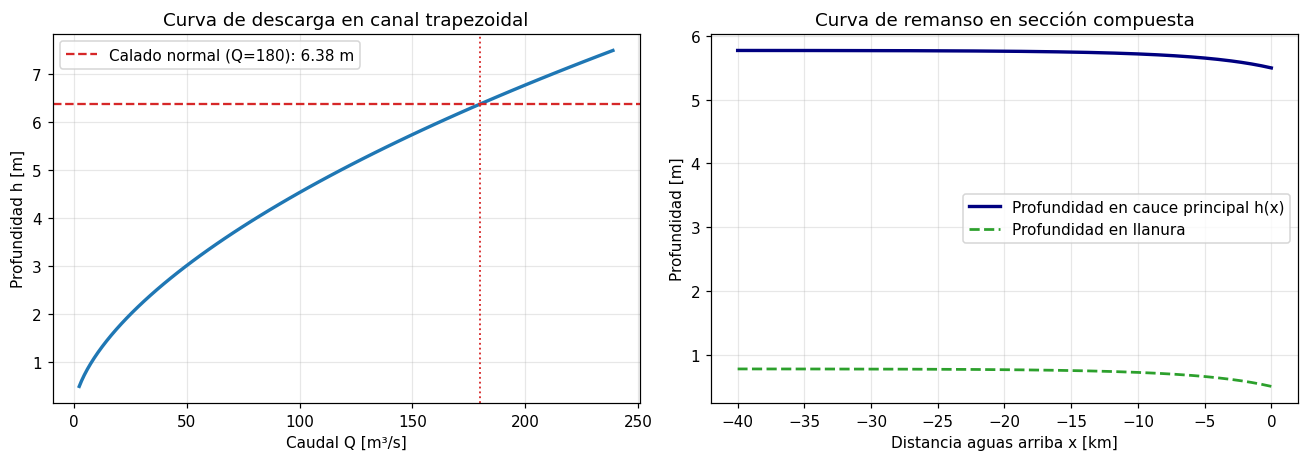

In [2]:
depths = np.linspace(0.5, 7.5, 60)
trap = sm.rivers.trapezoidal_channel_discharge(
    water_depth=depths, bottom_width=20.0, side_angle_deg=45.0, slope=0.0001, ks=0.08
)
h_normal = sm.rivers.solve_trapezoidal_depth(
    target_discharge=180.0, bottom_width=20.0, side_angle_deg=45.0, slope=0.0001, ks=0.08
)

# Cauce compuesto: cauce principal central más profundo y 2 llanuras laterales
comp = sm.rivers.compound_channel_flow(
    water_level=4.5,
    slope=0.00015,
    bed_levels=[2.5, 0.0, 2.5],
    widths=[120.0, 60.0, 120.0],
    ks_values=[0.15, 0.04, 0.15],
)

bw = sm.rivers.compound_channel_backwater(
    h0=5.5, slope=0.00015, discharge=900.0,
    widths=(80.0, 80.0, 60.0, 80.0, 80.0),
    ks_values=(0.10, 0.10, 0.03, 0.10, 0.10),
    h_floodplain=2.5, h_main_channel=5.0, dx=250.0, n_steps=160,
)

print(f"Calado normal en canal trapezoidal para Q=180 m³/s: h = {h_normal:.3f} m")
print(f"Cauce compuesto (nivel=4.5 m) -> Q total = {comp.total_discharge:.1f} m³/s | U media = {comp.mean_velocity:.2f} m/s")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.3))

ax1.plot(trap.discharge, depths, lw=2.2, color="tab:blue")
ax1.axhline(h_normal, color="tab:red", ls="--", label=f"Calado normal (Q=180): {h_normal:.2f} m")
ax1.axvline(180.0, color="tab:red", ls=":", lw=1.2)
ax1.set_xlabel("Caudal Q [m³/s]")
ax1.set_ylabel("Profundidad h [m]")
ax1.set_title("Curva de descarga en canal trapezoidal")
ax1.grid(alpha=0.3)
ax1.legend()

ax2.plot(bw.x / 1000.0, bw.water_depth, lw=2.2, color="navy", label="Profundidad en cauce principal h(x)")
ax2.plot(bw.x / 1000.0, bw.floodplain_depth, "--", lw=1.8, color="tab:green", label="Profundidad en llanura")
ax2.set_xlabel("Distancia aguas arriba x [km]")
ax2.set_ylabel("Profundidad [m]")
ax2.set_title("Curva de remanso en sección compuesta")
ax2.grid(alpha=0.3)
ax2.legend()

plt.tight_layout()
plt.show()


## 2. Asimetría Mareal (M2 + M4), Corriente por Viento y Flujo Estratificado

Un estuario presenta dominancia de flujo o reflujo según el desfase $\beta$ entre el armónico semidiurno $M_2$ y su primer sobrearmónico $M_4$. Simultáneamente, la acción del viento y los gradientes longitudinales de densidad ($\partial\rho / \partial x$) generan perfiles de recirculación vertical que gobiernan el transporte neto de sedimentos finos.


Asimetría (beta=350°): u_flood_max=1.30, u_ebb_max=0.77, fracción flujo=0.42


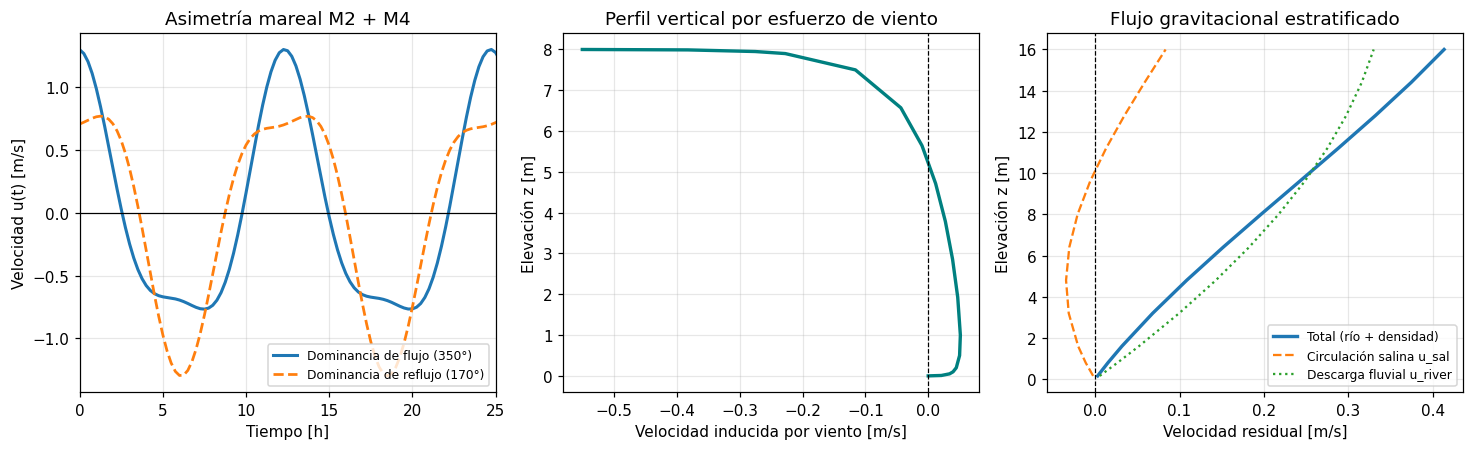

In [3]:
asym_flood = sm.currents.tidal_asymmetry_m2_m4(u1=1.0, u2=0.30, beta_deg=350.0, period_hours=12.4)
asym_ebb = sm.currents.tidal_asymmetry_m2_m4(u1=1.0, u2=0.30, beta_deg=170.0, period_hours=12.4)

wind_prof = sm.currents.wind_induced_velocity_profile(depth=8.0, u_star_wind=0.035, lam=0.5)
strat = sm.currents.stratified_density_flow_profile(
    depth=16.0, u_river=0.20, u_peak=1.0, d_rho_dx=0.00015, chezy=50.0, gamma=0.005
)

print(f"Asimetría (beta=350°): u_flood_max={asym_flood.u_flood_max:.2f}, u_ebb_max={asym_flood.u_ebb_max:.2f}, fracción flujo={asym_flood.flood_duration_fraction:.2f}")

fig, axes = plt.subplots(1, 3, figsize=(13.5, 4.2))

axes[0].plot(asym_flood.time_hours, asym_flood.u_total, label="Dominancia de flujo (350°)", lw=2)
axes[0].plot(asym_ebb.time_hours, asym_ebb.u_total, "--", label="Dominancia de reflujo (170°)", lw=1.8)
axes[0].axhline(0.0, color="k", lw=0.8)
axes[0].set_xlim(0, 25)
axes[0].set_xlabel("Tiempo [h]")
axes[0].set_ylabel("Velocidad u(t) [m/s]")
axes[0].set_title("Asimetría mareal M2 + M4")
axes[0].grid(alpha=0.3)
axes[0].legend(fontsize=8)

axes[1].plot(wind_prof.u, wind_prof.z, lw=2.2, color="teal")
axes[1].axvline(0.0, color="k", ls="--", lw=0.8)
axes[1].set_xlabel("Velocidad inducida por viento [m/s]")
axes[1].set_ylabel("Elevación z [m]")
axes[1].set_title("Perfil vertical por esfuerzo de viento")
axes[1].grid(alpha=0.3)

axes[2].plot(strat.u_total, strat.z, lw=2.2, label="Total (río + densidad)")
axes[2].plot(strat.u_sal, strat.z, "--", label="Circulación salina u_sal")
axes[2].plot(strat.u_river, strat.z, ":", label="Descarga fluvial u_river")
axes[2].axvline(0.0, color="k", ls="--", lw=0.8)
axes[2].set_xlabel("Velocidad residual [m/s]")
axes[2].set_ylabel("Elevación z [m]")
axes[2].set_title("Flujo gravitacional estratificado")
axes[2].grid(alpha=0.3)
axes[2].legend(fontsize=8)

plt.tight_layout()
plt.show()


## 3. Propagación de Marea e Intrusión Salina en Estuarios

Evaluamos la evolución longitudinal de la amplitud de marea $\eta(x)$ en un estuario convergente (`tidal_analytical_no_reflection`) y la distribución longitudinal de salinidad mediante los modelos de **Kuijper y van Rijn** (`tidal_salinity_kuijper`) y estacionario (`salinity_van_rijn_steady`).


Longitud máxima intrusión salina (Kuijper): Ls_max = 90.76 km
Intrusión estacionaria van Rijn -> Prismático: 21.33 km | Convergente: 16.11 km


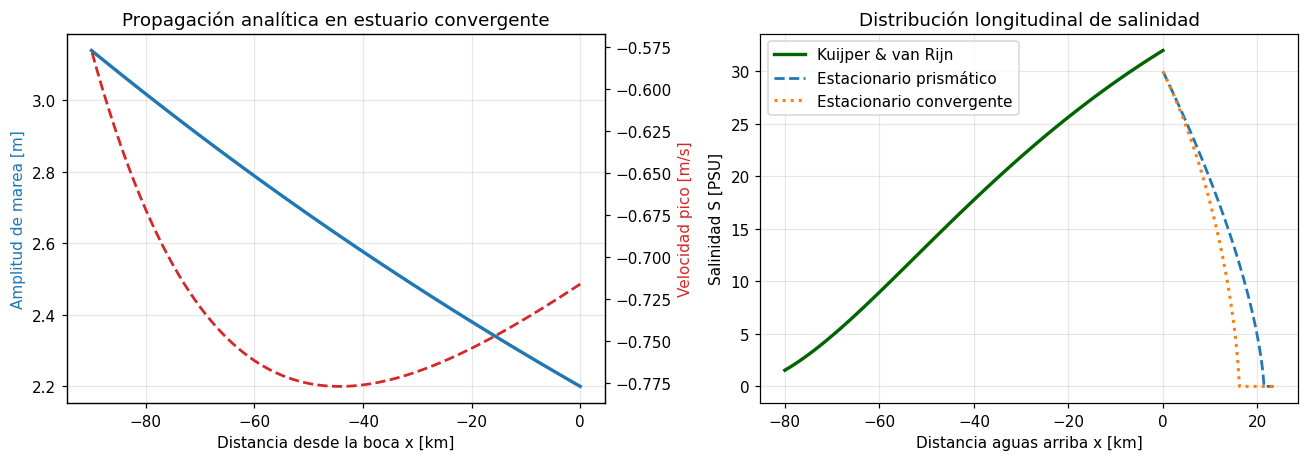

In [4]:
tide = sm.tides.tidal_analytical_no_reflection(
    eta0=2.2, h0=14.0, b0=600.0, period_s=44700.0, l_b=30000.0, length=90000.0, k_s=0.05, q_river=200.0
)
sal_kuijper = sm.tides.tidal_salinity_kuijper(
    eta0=2.1, h0=10.0, b0=15000.0, period_s=45000.0, l_b=25000.0, length=80000.0,
    q_river=120.0, s0=32.0
)
sal_steady = sm.tides.salinity_van_rijn_steady(
    q_river=250.0, h0=10.0, b0=800.0, s0=30.0, l_b=30000.0, u_max=1.0
)

print(f"Longitud máxima intrusión salina (Kuijper): Ls_max = {sal_kuijper.ls_max_kuijper/1000:.2f} km")
print(f"Intrusión estacionaria van Rijn -> Prismático: {sal_steady.ls_prismatic/1000:.2f} km | Convergente: {sal_steady.ls_converging/1000:.2f} km")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.3))

ax1.plot(tide.x / 1000.0, tide.eta_amplitude, color="tab:blue", lw=2.2, label="Amplitud mareal eta [m]")
ax1_t = ax1.twinx()
ax1_t.plot(tide.x / 1000.0, tide.u_flood_peak, "--", color="tab:red", lw=1.8, label="Pico de flujo [m/s]")
ax1.set_xlabel("Distancia desde la boca x [km]")
ax1.set_ylabel("Amplitud de marea [m]", color="tab:blue")
ax1_t.set_ylabel("Velocidad pico [m/s]", color="tab:red")
ax1.set_title("Propagación analítica en estuario convergente")
ax1.grid(alpha=0.3)

ax2.plot(sal_kuijper.x / 1000.0, sal_kuijper.salinity, lw=2.2, color="darkgreen", label="Kuijper & van Rijn")
ax2.plot(sal_steady.x / 1000.0, sal_steady.salinity_prismatic, "--", lw=1.8, label="Estacionario prismático")
ax2.plot(sal_steady.x / 1000.0, sal_steady.salinity_converging, ":", lw=2.0, label="Estacionario convergente")
ax2.set_xlabel("Distancia aguas arriba x [km]")
ax2.set_ylabel("Salinidad S [PSU]")
ax2.set_title("Distribución longitudinal de salinidad")
ax2.grid(alpha=0.3)
ax2.legend()

plt.tight_layout()
plt.show()


### Ejercicios propuestos
1. Reduzca el caudal fluvial `q_river` de `120` a `40 m³/s` en `tidal_salinity_kuijper` y cuantifique cuánto avanza la cuña salina aguas arriba.
2. Analice la sensibilidad de la corriente residual superficial en `wind_induced_velocity_profile` frente a la velocidad de fricción del viento `u_star_wind`.
